# DSA 5205 Assignment 1

## Task 1

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# Task 1: Misspecified simulation with ridge
# ============================================================

SEED = 5205

# Sample sizes
T_tr = 500
T_te = 2000

# True DGP complexity c = P / T_tr = 10
c = 10
P = int(c * T_tr)

# Signal strength ||beta*||^2 = b_star
b_star = 1.0

# Observed complexity cq = P1 / T_tr
cq_grid = np.array([
    0.50, 0.75, 0.90, 0.95, 0.98,
    1.02, 1.05, 1.10, 1.25, 1.50,
    2.00, 3.00, 5.00, 7.00, 10.00
])

# Ridge shrinkage z
z_grid = np.array([
    0.0, 0.1, 0.25, 0.5, 1.0,
    2.0, 5.0, 10.0, 25.0, 50.0, 100.0
])



Generating the data

In [28]:
def generate_dgp(T_tr, T_te, P, b_star, seed=5205):
    rng = np.random.default_rng(seed)

    T = T_tr + T_te

    # --------------------------------------------------------
    # 1. Signals: S_t ~ N(0, I_P)
    # --------------------------------------------------------
    S = rng.standard_normal((T, P))

    # --------------------------------------------------------
    # 2. Dense isotropic beta*
    # --------------------------------------------------------
    beta_star = rng.standard_normal(P)

    # Normalize so ||beta*||^2 = b_star
    beta_star *= np.sqrt(b_star) / np.linalg.norm(beta_star)

    print("||beta_star||^2 =", np.sum(beta_star**2))

    # --------------------------------------------------------
    # 3. Returns
    # R_{t+1} = S_t' beta* + epsilon_{t+1}
    # --------------------------------------------------------
    epsilon = rng.standard_normal(T)

    R = S @ beta_star + epsilon

    # --------------------------------------------------------
    # 4. Randomly permute columns ONCE
    # Same permutation is used for every q
    # --------------------------------------------------------
    perm = rng.permutation(P)

    S = S[:, perm]
    beta_star = beta_star[perm]

    # --------------------------------------------------------
    # 5. Train/test split
    # --------------------------------------------------------
    S_train = S[:T_tr]
    S_test = S[T_tr:]

    R_train = R[:T_tr]
    R_test = R[T_tr:]

    return S_train, R_train, S_test, R_test, beta_star


S_train, R_train, S_test, R_test, beta_star = generate_dgp(
    T_tr=T_tr,
    T_te=T_te,
    P=P,
    b_star=b_star,
    seed=SEED
)

print("Training signals:", S_train.shape)
print("Test signals:", S_test.shape)
print("Training returns:", R_train.shape)
print("Test returns:", R_test.shape)

||beta_star||^2 = 1.000000000000001
Training signals: (500, 5000)
Test signals: (2000, 5000)
Training returns: (500,)
Test returns: (2000,)


In [29]:
from sklearn.linear_model import Ridge

def ridge_path(X, y, z_grid):

    T = X.shape[0]
    betas = {}

    for z in z_grid:

        if z == 0:
            # Minimum-norm OLS solution
            beta_hat = np.linalg.pinv(X) @ y

        else:
            model = Ridge(
                alpha=z * T,
                fit_intercept=False,
                solver="svd"
            )

            model.fit(X, y)
            beta_hat = model.coef_

        betas[z] = beta_hat

    return betas

In [30]:
def compute_metrics(beta_hat, X_test, y_test):

    # Predicted returns
    y_hat = X_test @ beta_hat

    # Paper R2
    r2_paper = (
        1 - np.mean((y_test - y_hat)**2)
        / np.mean(y_test**2)
    )

    # KMZ R2 identity
    r2_identity = (
        2 * np.mean(y_hat * y_test)
        - np.mean(y_hat**2)
    ) / np.mean(y_test**2)

    # Timing returns
    timing_return = y_hat * y_test

    expected_timing_return = np.mean(timing_return)

    # KMZ Sharpe ratio
    denominator = np.sqrt(np.mean(timing_return**2))

    if denominator > 0:
        sharpe = expected_timing_return / denominator
    else:
        sharpe = np.nan

    # Variance-based Sharpe
    std_timing = np.std(timing_return)

    if std_timing > 0:
        sharpe_var = expected_timing_return / std_timing
    else:
        sharpe_var = np.nan

    # Coefficient norm
    beta_norm_sq = np.sum(beta_hat**2)

    return {
        "R2_paper": r2_paper,
        "R2_identity_check": r2_identity,
        "E_timing_return": expected_timing_return,
        "SR": sharpe,
        "SR_var": sharpe_var,
        "beta_norm_sq": beta_norm_sq
    }

Execution of task 1

In [31]:
results = []

for cq in cq_grid:

    # Number of observed predictors
    P1 = int(round(cq * T_tr))

    # q = fraction of the true P signals observed
    q = P1 / P

    print(
        f"cq={cq:5.2f} | "
        f"P1={P1:4d} | "
        f"q={q:.3f}"
    )

    # --------------------------------------------------------
    # Observe only first P1 predictors
    # --------------------------------------------------------
    X_train = S_train[:, :P1]
    X_test = S_test[:, :P1]

    # --------------------------------------------------------
    # Fit entire ridge path
    # --------------------------------------------------------
    beta_path = ridge_path(
        X_train,
        R_train,
        z_grid
    )

    # --------------------------------------------------------
    # Evaluate each z OOS
    # --------------------------------------------------------
    for z in z_grid:

        beta_hat = beta_path[z]

        metrics = compute_metrics(
            beta_hat,
            X_test,
            R_test
        )

        results.append({
            "cq": cq,
            "P1": P1,
            "q": q,
            "z": z,
            **metrics
        })


results_df = pd.DataFrame(results)

results_df.head()

cq= 0.50 | P1= 250 | q=0.050
cq= 0.75 | P1= 375 | q=0.075
cq= 0.90 | P1= 450 | q=0.090
cq= 0.95 | P1= 475 | q=0.095
cq= 0.98 | P1= 490 | q=0.098
cq= 1.02 | P1= 510 | q=0.102
cq= 1.05 | P1= 525 | q=0.105
cq= 1.10 | P1= 550 | q=0.110
cq= 1.25 | P1= 625 | q=0.125
cq= 1.50 | P1= 750 | q=0.150
cq= 2.00 | P1=1000 | q=0.200
cq= 3.00 | P1=1500 | q=0.300
cq= 5.00 | P1=2500 | q=0.500
cq= 7.00 | P1=3500 | q=0.700
cq=10.00 | P1=5000 | q=1.000


,cq,P1,q,z,R2_paper,R2_identity_check,E_timing_return,SR,SR_var,beta_norm_sq
0,0.5,250,0.05,0.00,-0.725466,-0.725466,0.009910,0.005612,0.005612,1.592340
1,0.5,250,0.05,0.10,-0.435556,-0.435556,0.009392,0.006807,0.006807,0.969860
2,0.5,250,0.05,0.25,-0.274879,-0.274879,0.007308,0.006645,0.006645,0.618595
3,0.5,250,0.05,0.50,-0.166457,-0.166457,0.004892,0.005709,0.005709,0.377583
4,0.5,250,0.05,1.00,-0.087046,-0.087046,0.002573,0.004154,0.004154,0.198469


In [32]:
def plot_metric(results_df, metric, ylabel, title):

    plt.figure(figsize=(10, 6))

    for z in z_grid:

        subset = results_df[
            results_df["z"] == z
        ].sort_values("cq")

        plt.plot(
            subset["cq"],
            subset[metric],
            marker="o",
            markersize=3,
            label=f"z={z:g}"
        )

    # Interpolation threshold
    plt.axvline(
        1.0,
        linestyle="--",
        linewidth=1,
        label="cq = 1"
    )

    plt.xlabel(r"Observed complexity $cq=P_1/T_{tr}$")
    plt.ylabel(ylabel)
    plt.title(title)

    plt.legend(
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

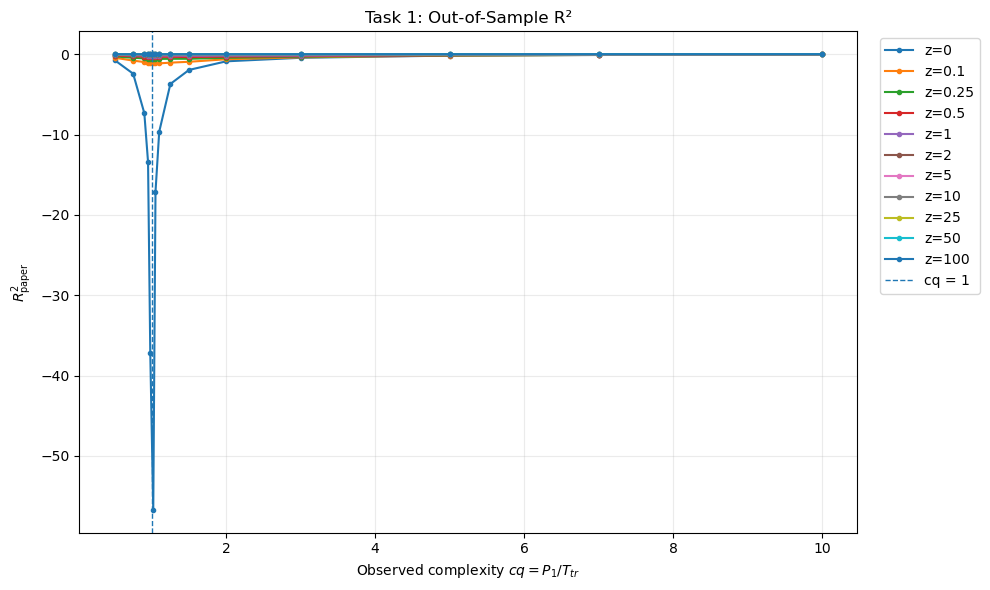

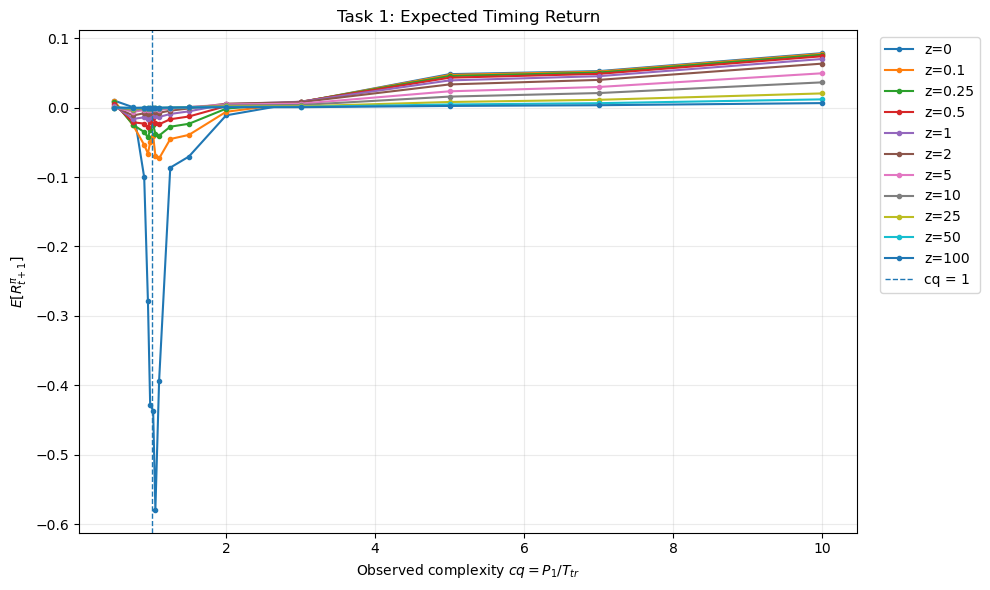

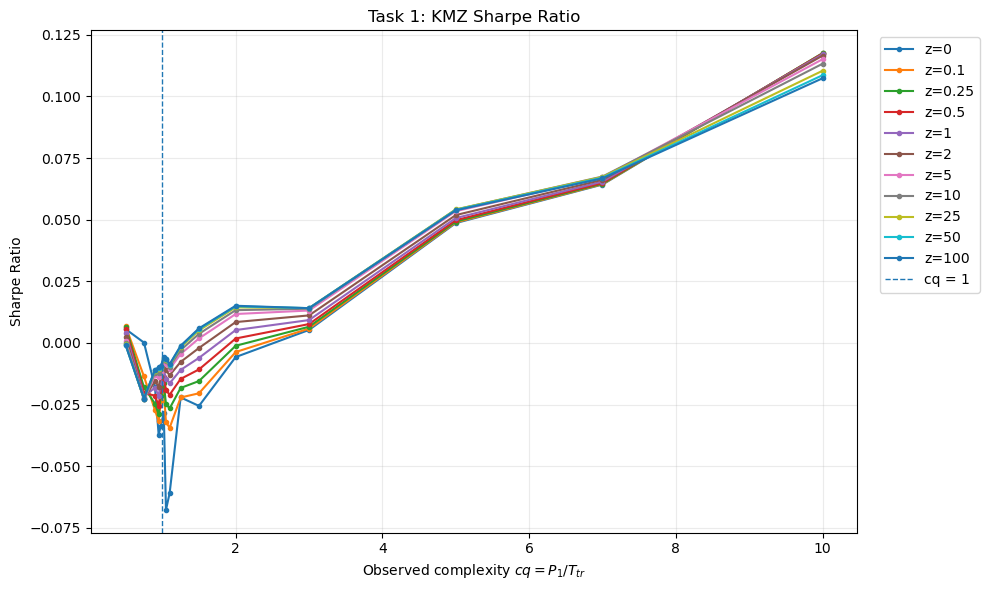

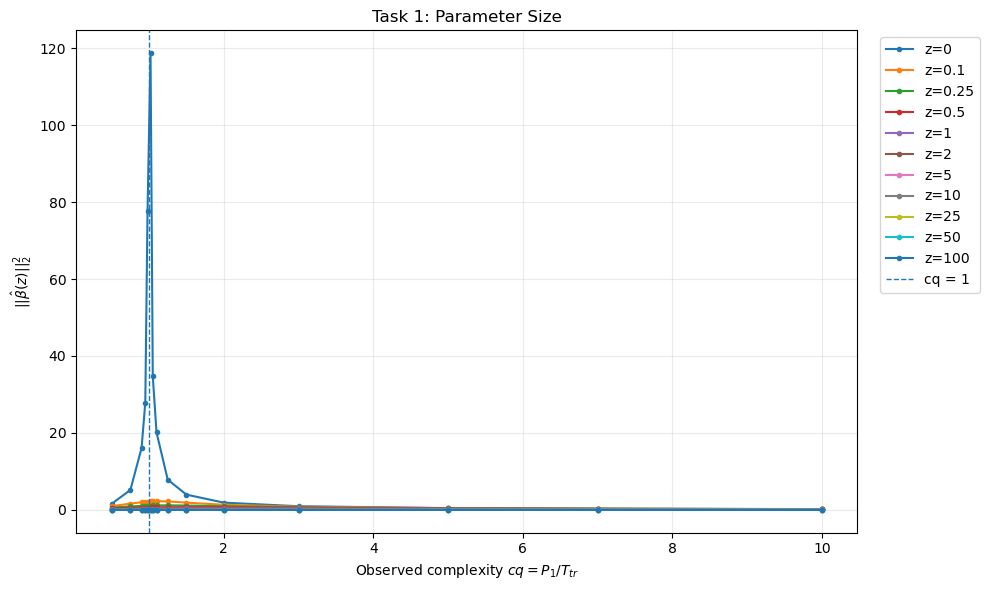

In [33]:
plot_metric(
    results_df,
    "R2_paper",
    r"$R^2_{\mathrm{paper}}$",
    "Task 1: Out-of-Sample R²"
)

plot_metric(
    results_df,
    "E_timing_return",
    r"$E[R^\pi_{t+1}]$",
    "Task 1: Expected Timing Return"
)

plot_metric(
    results_df,
    "SR",
    "Sharpe Ratio",
    "Task 1: KMZ Sharpe Ratio"
)

plot_metric(
    results_df,
    "beta_norm_sq",
    r"$||\hat{\beta}(z)||_2^2$",
    "Task 1: Parameter Size"
)

## Task 2

For task 2 I have decided to use lasso regression.

In [34]:
from sklearn.linear_model import Lasso
from sklearn.exceptions import ConvergenceWarning

# ============================================================
# Ensuring that we are using the same data
# ============================================================

assert S_train.shape == (T_tr, P)
assert S_test.shape == (T_te, P)

assert len(R_train) == T_tr
assert len(R_test) == T_te

assert np.isclose(c, 10)

print("Task 2 reusing Task 1 data successfully.")

print("Training data:", S_train.shape)
print("Testing data:", S_test.shape)
print("True complexity:", P / T_tr)

Task 2 reusing Task 1 data successfully.
Training data: (500, 5000)
Testing data: (2000, 5000)
True complexity: 10.0


Parameter that we will be using for lasso regression

In [35]:
# Lasso regularization strengths
lambda_grid = np.array([
    0.001,
    0.005,
    0.01,
    0.025,
    0.05,
    0.1,
    0.25,
    0.5,
    1.0
])

# same cq grid as Task 1
cq_grid_task2 = cq_grid.copy()


In [36]:
def fit_lasso(X_train, y_train, alpha):

    model = Lasso(
        alpha=alpha,
        fit_intercept=False,
        max_iter=20000,
        tol=1e-4,
        selection="cyclic"
    )

    model.fit(X_train, y_train)

    return model.coef_

In [37]:
# ============================================================
# Executing the lasso regression
# ============================================================

results_lasso = []

for cq in cq_grid_task2:

    # Same number of observed predictors as Task 1
    P1 = int(round(cq * T_tr))

    q = P1 / P

    print(f"Running Lasso: cq={cq:.2f}, P1={P1}")

    # EXACT same observed features
    X_train = S_train[:, :P1]
    X_test = S_test[:, :P1]

    for lam in lambda_grid:

        # Fit Lasso
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter(
                "always", ConvergenceWarning
            )

            beta_hat = fit_lasso(
                X_train,
                R_train,
                alpha=lam
            )

        converged = not any(
            issubclass(w.category, ConvergenceWarning)
            for w in caught
        )

        # Reuse the SAME metric function from Task 1
        metrics = compute_metrics(
            beta_hat,
            X_test,
            R_test
        )

        # Number of selected predictors
        n_nonzero = np.sum(np.abs(beta_hat) > 1e-8)

        results_lasso.append({
            "cq": cq,
            "P1": P1,
            "q": q,
            "lambda": lam,
            "n_nonzero": n_nonzero,
            "converged": converged,
            **metrics
        })


results_lasso_df = pd.DataFrame(results_lasso)

print(results_lasso_df.head())
print(
    "Non-converged fits:",
    (~results_lasso_df["converged"]).sum()
)

Running Lasso: cq=0.50, P1=250
Running Lasso: cq=0.75, P1=375
Running Lasso: cq=0.90, P1=450
Running Lasso: cq=0.95, P1=475
Running Lasso: cq=0.98, P1=490
Running Lasso: cq=1.02, P1=510
Running Lasso: cq=1.05, P1=525
Running Lasso: cq=1.10, P1=550
Running Lasso: cq=1.25, P1=625
Running Lasso: cq=1.50, P1=750
Running Lasso: cq=2.00, P1=1000
Running Lasso: cq=3.00, P1=1500
Running Lasso: cq=5.00, P1=2500
Running Lasso: cq=7.00, P1=3500
Running Lasso: cq=10.00, P1=5000
    cq   P1     q  lambda  n_nonzero  converged  R2_paper  R2_identity_check  \
0  0.5  250  0.05   0.001        241       True -0.681398          -0.681398   
1  0.5  250  0.05   0.005        226       True -0.539741          -0.539741   
2  0.5  250  0.05   0.010        215       True -0.408760          -0.408760   
3  0.5  250  0.05   0.025        164       True -0.193101          -0.193101   
4  0.5  250  0.05   0.050         95       True -0.078355          -0.078355   

   E_timing_return        SR    SR_var  beta_nor

In [38]:
def plot_lasso_metric(df, metric, ylabel, title):

    plt.figure(figsize=(10, 6))

    for lam in lambda_grid:

        subset = df[
            df["lambda"] == lam
        ].sort_values("cq")

        plt.plot(
            subset["cq"],
            subset[metric],
            marker="o",
            markersize=3,
            label=f"lambda={lam:g}"
        )

    plt.axvline(
        x=1,
        color="black",
        linestyle="--",
        linewidth=1,
        label="Interpolation threshold"
    )

    plt.xlabel(r"Observed complexity $cq=P_1/T_{tr}$")
    plt.ylabel(ylabel)
    plt.title(title)

    plt.legend(
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

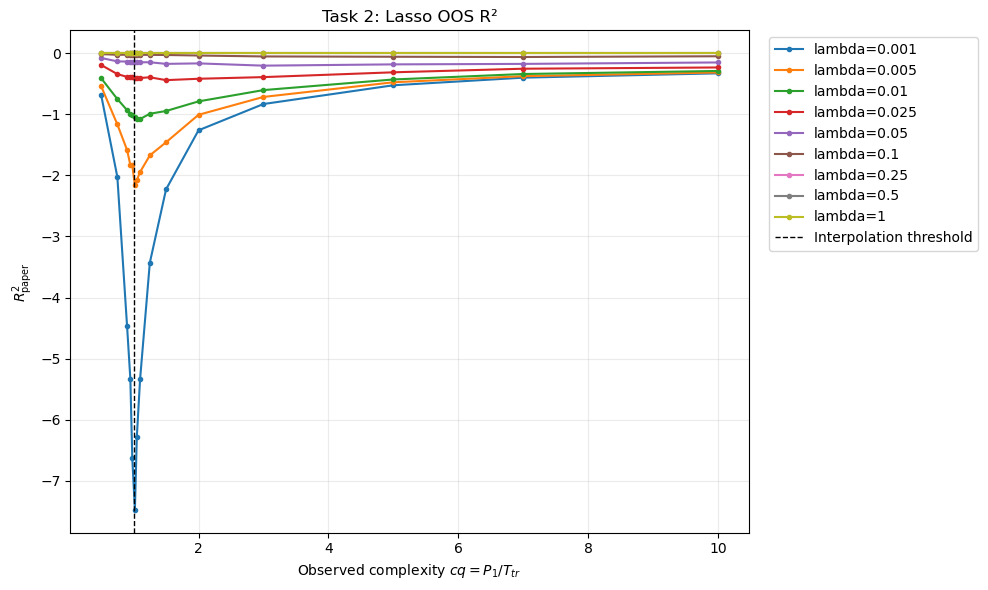

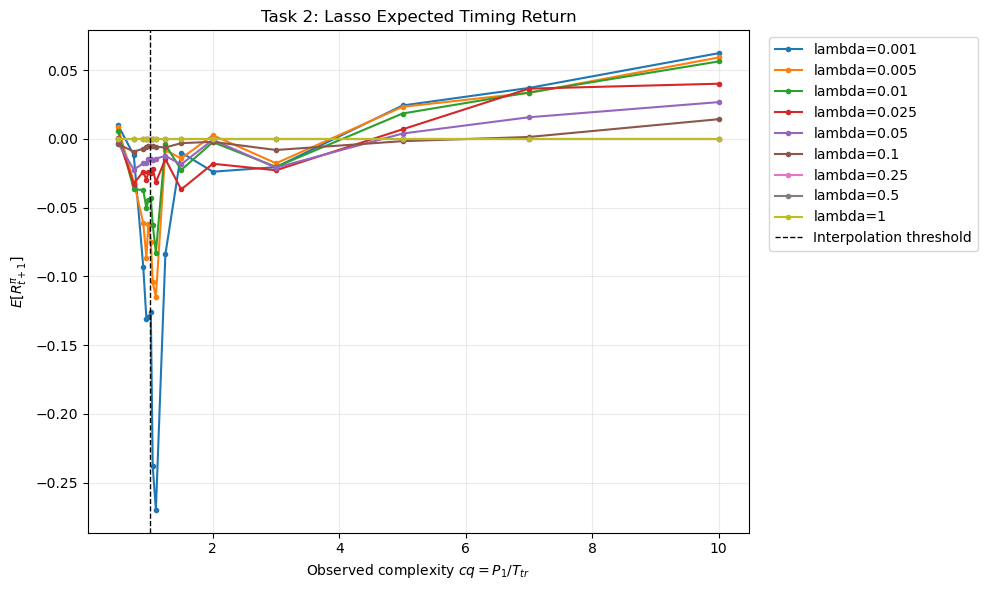

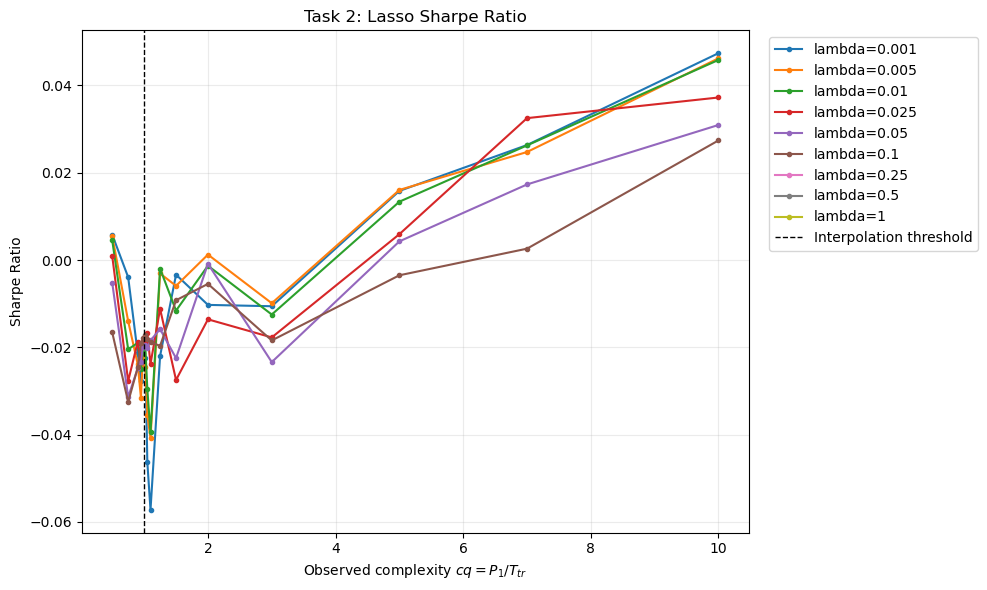

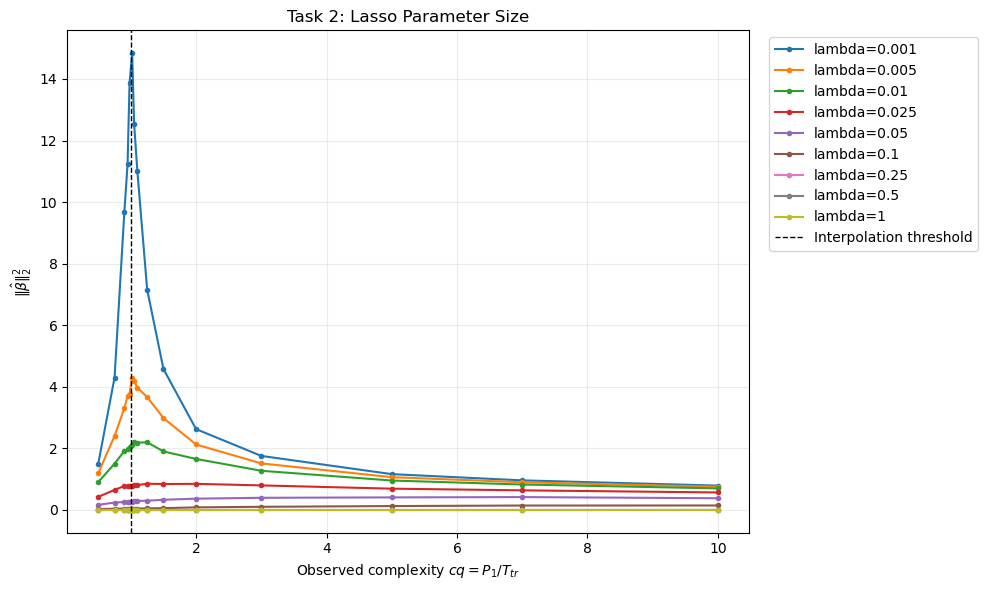

In [39]:
plot_lasso_metric(
    results_lasso_df,
    "R2_paper",
    r"$R^2_{\mathrm{paper}}$",
    "Task 2: Lasso OOS R²"
)

plot_lasso_metric(
    results_lasso_df,
    "E_timing_return",
    r"$E[R^\pi_{t+1}]$",
    "Task 2: Lasso Expected Timing Return"
)

plot_lasso_metric(
    results_lasso_df,
    "SR",
    "Sharpe Ratio",
    "Task 2: Lasso Sharpe Ratio"
)

plot_lasso_metric(
    results_lasso_df,
    "beta_norm_sq",
    r"$\|\hat{\beta}\|_2^2$",
    "Task 2: Lasso Parameter Size"
)

## Task 3

In [74]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

import warnings

warnings.filterwarnings(
    "ignore",
    category=RuntimeWarning,
    message="invalid value encountered in double_scalars"
)



In [75]:
def compute_metrics(y_true, y_pred):

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    # KMZ paper R-squared
    r2_paper = 1 - np.mean((y_true - y_pred)**2) / np.mean(y_true**2)

    # Timing return
    timing_return = y_true * y_pred

    expected_timing_return = np.mean(timing_return)

    # KMZ Sharpe ratio (uncentered denominator)
    sharpe = (
        np.mean(timing_return)
        / np.sqrt(np.mean(timing_return**2))
    )

    # Variance-based Sharpe
    sharpe_var = (
        np.mean(timing_return)
        / np.std(timing_return)
    )

    return {
        "R2_paper": r2_paper,
        "Expected_Timing_Return": expected_timing_return,
        "Sharpe": sharpe,
        "Sharpe_var": sharpe_var
    }

In [76]:
def load_dataset(train_path):

    df = pd.read_csv(train_path)

    feature_cols = [
        col for col in df.columns
        if col.startswith("feature")
    ]

    feature_cols = sorted(
        feature_cols,
        key=lambda x: int(x.replace("feature", ""))
    )

    df = df.sort_values("t").reset_index(drop=True)

    X = df[feature_cols].values
    y = df["return"].values

    split_idx = int(0.8 * len(df))

    X_train = X[:split_idx]
    X_val = X[split_idx:]

    y_train = y[:split_idx]
    y_val = y[split_idx:]

    print("Number of features:", X.shape[1])
    print("Training observations:", len(y_train))
    print("Validation observations:", len(y_val))

    return X_train, X_val, y_train, y_val

In [77]:
def compare_models(X_train, X_val, y_train, y_val):

    results = []

    # Ridge z grid
    ridge_grid = [0.01, 0.1, 0.25, 0.5, 1, 2, 5, 10, 25, 50, 100]

    # Lasso alpha grid
    lasso_grid = np.logspace(-5, 0, 15)

    models = {
        "Ridge": ridge_grid,
        "Lasso": lasso_grid
    }

    for model_name, grid in models.items():

        for lam in grid:

            if model_name == "Ridge":

                model = Pipeline([
                    ("scaler", StandardScaler()),
                    ("regressor", Ridge(
                        alpha=lam * len(y_train),
                        fit_intercept=False
                    ))
                ])

            else:

                model = Pipeline([
                    ("scaler", StandardScaler()),
                    ("regressor", Lasso(
                        alpha=lam,
                        fit_intercept=False,
                        max_iter=20000,
                        tol=1e-4
                    ))
                ])

            with warnings.catch_warnings():
                warnings.simplefilter("ignore", ConvergenceWarning)
                model.fit(X_train, y_train)

            y_pred = model.predict(X_val)

            metrics = compute_metrics(y_val, y_pred)

            results.append({
                "Model": model_name,
                "Lambda": lam,
                **metrics
            })

    results_df = pd.DataFrame(results)

    return results_df

# Please include path to dataset below

In [78]:
datasets = {
    "A": "pairA_train.csv",
    "B": "pairB_train.csv",
    "C": "pairC_train.csv"
}

all_results = {}

for dataset_name, train_path in datasets.items():

    print(f"\n========== DATASET {dataset_name} ==========")

    X_train, X_val, y_train, y_val = load_dataset(train_path)

    results_df = compare_models(
        X_train, X_val, y_train, y_val
    )

    all_results[dataset_name] = results_df

    print("\nBest Ridge:")
    print(
        results_df[results_df["Model"] == "Ridge"]
        .sort_values("Sharpe", ascending=False)
        .head(1)
        .to_string(index=False)
    )

    print("\nBest Lasso:")
    print(
        results_df[results_df["Model"] == "Lasso"]
        .sort_values("Sharpe", ascending=False)
        .head(1)
        .to_string(index=False)
    )


========== DATASET A ==========
Number of features: 600
Training observations: 480
Validation observations: 120

Best Ridge:
Model  Lambda  R2_paper  Expected_Timing_Return   Sharpe  Sharpe_var
Ridge     2.0  0.029361                0.084281 0.173336       0.176

Best Lasso:
Model   Lambda  R2_paper  Expected_Timing_Return   Sharpe  Sharpe_var
Lasso 0.016379 -0.331547                0.137818 0.127822    0.128879

========== DATASET B ==========
Number of features: 2400
Training observations: 192
Validation observations: 48

Best Ridge:
Model  Lambda  R2_paper  Expected_Timing_Return    Sharpe  Sharpe_var
Ridge    0.01  -0.15803               -0.038319 -0.184605   -0.187834

Best Lasso:
Model   Lambda  R2_paper  Expected_Timing_Return   Sharpe  Sharpe_var
Lasso 0.084834 -0.013358                0.094912 0.239222    0.246376

========== DATASET C ==========
Number of features: 1800
Training observations: 288
Validation observations: 72

Best Ridge:
Model  Lambda  R2_paper  Expected_Timi

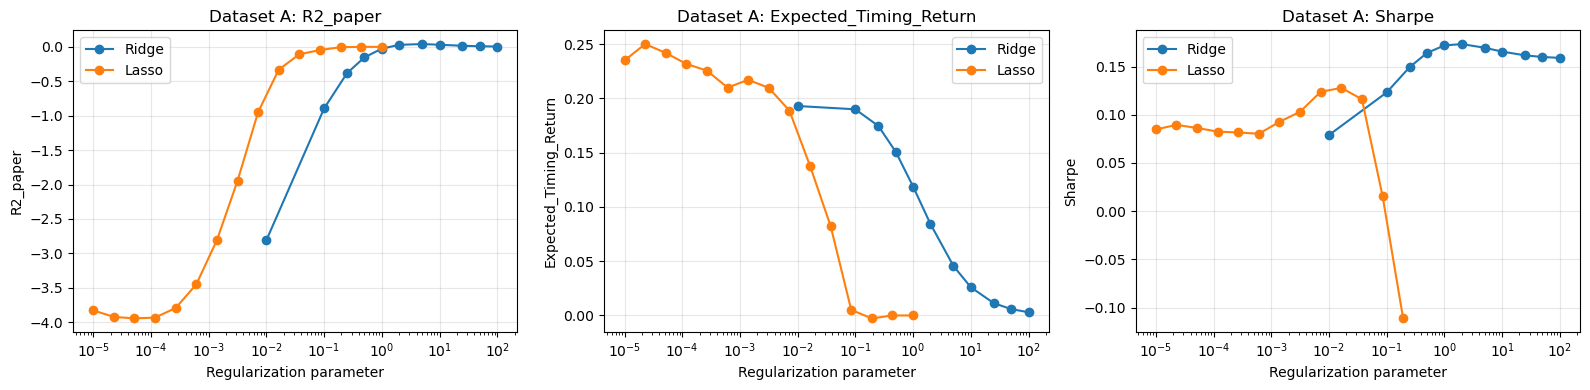

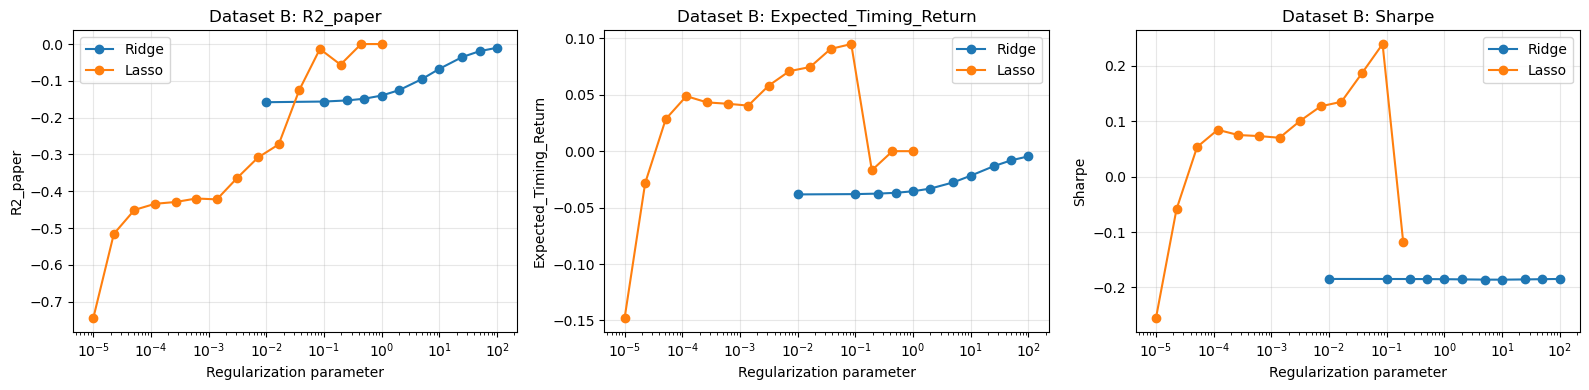

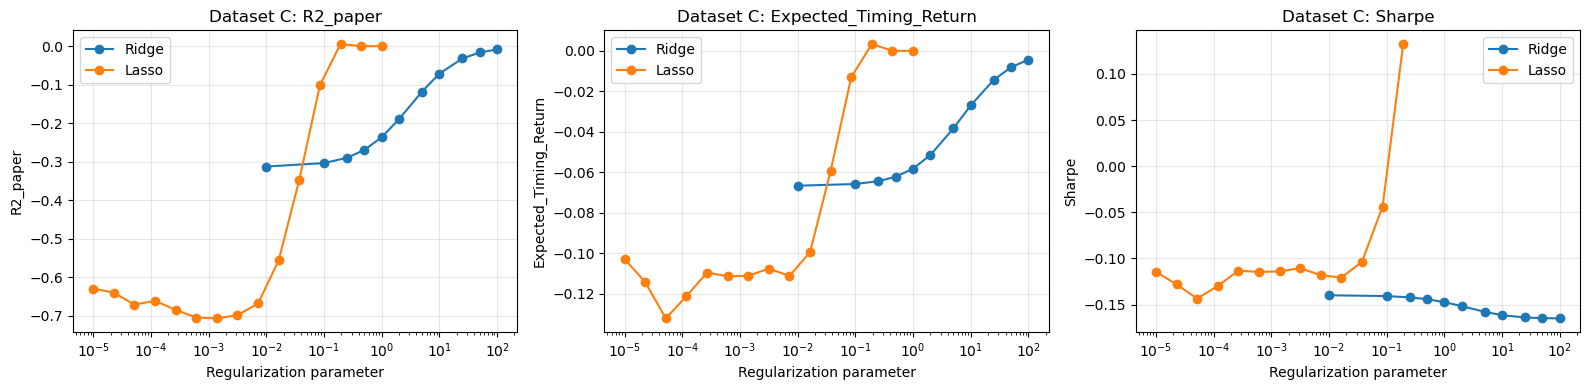

In [79]:
for dataset_name, results_df in all_results.items():

    fig, axes = plt.subplots(1, 3, figsize=(16, 4))

    metrics = [
        "R2_paper",
        "Expected_Timing_Return",
        "Sharpe"
    ]

    for ax, metric in zip(axes, metrics):

        for model_name in ["Ridge", "Lasso"]:

            subset = results_df[
                results_df["Model"] == model_name
            ]

            ax.plot(
                subset["Lambda"],
                subset[metric],
                marker="o",
                label=model_name
            )

        ax.set_xscale("log")
        ax.set_xlabel("Regularization parameter")
        ax.set_ylabel(metric)
        ax.set_title(f"Dataset {dataset_name}: {metric}")
        ax.legend()
        ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

In [80]:
summary = []

for dataset_name, results_df in all_results.items():

    for model_name in ["Ridge", "Lasso"]:

        subset = results_df[
            results_df["Model"] == model_name
        ]

        best = subset.loc[subset["Sharpe"].idxmax()]

        summary.append({
            "Dataset": dataset_name,
            "Model": model_name,
            "Best_Lambda": best["Lambda"],
            "R2_paper": best["R2_paper"],
            "Expected_Timing_Return": best["Expected_Timing_Return"],
            "Sharpe": best["Sharpe"]
        })

summary_df = pd.DataFrame(summary)

display(summary_df)

,Dataset,Model,Best_Lambda,R2_paper,Expected_Timing_Return,Sharpe
0,A,Ridge,2.000000,0.029361,0.084281,0.173336
1,A,Lasso,0.016379,-0.331547,0.137818,0.127822
2,B,Ridge,0.010000,-0.158030,-0.038319,-0.184605
3,B,Lasso,0.084834,-0.013358,0.094912,0.239222
4,C,Ridge,0.010000,-0.312532,-0.066570,-0.139859
5,C,Lasso,0.193070,0.005528,0.003365,0.132406


Based on the r^2 results and the sharpe ratio I would pick Ridge regression for Dataset A and Lasso for dataset B and C

In [73]:
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.linear_model import Ridge, Lasso
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter


# ============================================================
# 1. CONFIGURATION
# ============================================================

STUDENT_ID = "A0350886R"

# UPDATE FILE NAME HERE
files = {
    "A": {
        "train": "pairA_train.csv",
        "test": "pairA_test_features.csv",
        "model": "Ridge",
        "lambda": 2.0
    },
    "B": {
        "train": "pairB_train.csv",
        "test": "pairB_test_features.csv",
        "model": "Lasso",
        "lambda": 0.084834
    },
    "C": {
        "train": "pairC_train.csv",
        "test": "pairC_test_features.csv",
        "model": "Lasso",
        "lambda": 0.193070
    }
}


# ============================================================
# 2. LOAD DATA AND GENERATE PREDICTIONS
# ============================================================

all_predictions = {}
summary = []

for dataset, config in files.items():

    print(f"\nProcessing Dataset {dataset}")

    # Load training and testing data
    train_df = pd.read_csv(config["train"])
    test_df = pd.read_csv(config["test"])

    # Identify training features in their original order
    feature_cols = [
        col for col in train_df.columns
        if col.startswith("feature")
    ]

    # Validate expected columns
    if not {"t", "return"}.issubset(train_df.columns):
        raise ValueError(
            f"Dataset {dataset}: missing training columns"
        )

    if "t" not in test_df.columns:
        raise ValueError(
            f"Dataset {dataset}: missing test time column"
        )

    test_features = [
        col for col in test_df.columns
        if col.startswith("feature")
    ]

    if set(feature_cols) != set(test_features):
        raise ValueError(
            f"Dataset {dataset}: train/test features differ"
        )

    # Validate test schema
    if set(test_df.columns) != set(["t"] + feature_cols):
        raise ValueError(
            f"Dataset {dataset}: unexpected test columns"
        )

    # Validate data quality
    if train_df.isna().any().any() or test_df.isna().any().any():
        raise ValueError(
            f"Dataset {dataset}: missing values detected"
        )

    for name, df in [("train", train_df), ("test", test_df)]:
        if not df["t"].is_unique:
            raise ValueError(f"{dataset} {name}: duplicate t")

        if not df["t"].is_monotonic_increasing:
            raise ValueError(f"{dataset} {name}: t not increasing")

    # Align test columns with training columns
    X_train = train_df[feature_cols].to_numpy(dtype=float)
    y_train = train_df["return"].to_numpy(dtype=float)

    X_test = test_df[feature_cols].to_numpy(dtype=float)

    # --------------------------------------------------------
    # Fit selected model
    # --------------------------------------------------------

    T_tr = len(X_train)

    if config["model"] == "Ridge":

        # KMZ Ridge scaling: alpha = z * T_tr
        model = Ridge(
            alpha=config["lambda"] * T_tr,
            fit_intercept=False,
            solver="svd"
        )

    elif config["model"] == "Lasso":

        model = Lasso(
            alpha=config["lambda"],
            fit_intercept=False,
            max_iter=50000,
            tol=1e-5
        )

    else:
        raise ValueError("Unknown model")

    # Train on the FULL training dataset
    model.fit(X_train, y_train)

    # Generate test predictions
    yhat = model.predict(X_test)

    if not np.isfinite(yhat).all():
        raise ValueError(
            f"Dataset {dataset}: invalid predictions"
        )

    # --------------------------------------------------------
    # Create predictions dataframe
    # --------------------------------------------------------

    predictions_df = pd.DataFrame({
        "t": test_df["t"].to_numpy(),
        "yhat": yhat
    })

    all_predictions[dataset] = predictions_df

    # Save submission-ready CSV
    csv_filename = (
        f"{STUDENT_ID}_predictions_{dataset}.csv"
    )

    predictions_df.to_csv(
        csv_filename,
        index=False,
        encoding="utf-8"
    )

    # Record summary information
    summary.append({
        "Dataset": dataset,
        "Model": config["model"],
        "Best_Lambda": config["lambda"],
        "Train_Size": len(X_train),
        "Test_Size": len(X_test),
        "Num_Features": len(feature_cols),
        "Mean_Predicted_Return": np.mean(yhat),
        "Std_Predicted_Return": np.std(yhat),
        "Num_Nonzero_Coefficients": np.sum(
            np.abs(model.coef_) > 1e-8
        )
    })

    print(f"Model: {config['model']}")
    print(f"Train size: {len(X_train)}")
    print(f"Test size: {len(X_test)}")
    print(f"Predictions saved: {csv_filename}")


# ============================================================
# 3. EXPORT TO EXCEL
# ============================================================

summary_df = pd.DataFrame(summary)

excel_filename = "Task3_Test_Predictions.xlsx"

with pd.ExcelWriter(
    excel_filename,
    engine="openpyxl"
) as writer:

    # Summary sheet
    summary_df.to_excel(
        writer,
        sheet_name="Model Summary",
        index=False
    )

    # Individual prediction sheets
    for dataset, predictions_df in all_predictions.items():

        predictions_df.to_excel(
            writer,
            sheet_name=f"Dataset {dataset}",
            index=False
        )

    # Apply basic formatting
    for ws in writer.book.worksheets:

        ws.freeze_panes = "A2"
        ws.sheet_view.showGridLines = False
        ws.auto_filter.ref = ws.dimensions

        for cell in ws[1]:
            cell.font = Font(
                bold=True,
                color="FFFFFF"
            )
            cell.fill = PatternFill(
                "solid",
                fgColor="17365D"
            )
            cell.alignment = Alignment(
                horizontal="center"
            )

        for column in ws.columns:
            letter = get_column_letter(column[0].column)
            max_length = max(
                len(str(cell.value or ""))
                for cell in column
            )
            ws.column_dimensions[letter].width = min(
                max(max_length + 3, 14),
                30
            )

        if ws.title.startswith("Dataset "):
            for row in ws.iter_rows(
                min_row=2,
                min_col=2,
                max_col=2
            ):
                row[0].number_format = "0.00000000"


print("\nExcel file created:", excel_filename)
print("\nModel Summary:")
print(summary_df)


Processing Dataset A
Model: Ridge
Train size: 600
Test size: 1000
Predictions saved: A0350886R_predictions_A.csv

Processing Dataset B
Model: Lasso
Train size: 240
Test size: 4000
Predictions saved: A0350886R_predictions_B.csv

Processing Dataset C
Model: Lasso
Train size: 360
Test size: 2000
Predictions saved: A0350886R_predictions_C.csv

Excel file created: Task3_Test_Predictions.xlsx

Model Summary:
  Dataset  Model  Best_Lambda  Train_Size  Test_Size  Num_Features  \
0       A  Ridge     2.000000         600       1000           600   
1       B  Lasso     0.084834         240       4000          2400   
2       C  Lasso     0.193070         360       2000          1800   

   Mean_Predicted_Return  Std_Predicted_Return  Num_Nonzero_Coefficients  
0               0.010011              0.321085                       600  
1              -0.003539              0.411794                        94  
2              -0.000710              0.018588                         1  


## Task 4

### Generalization and Overfitting in Financial Neural Networks

Montanari and Urbani (2025)'s paper showed that learning of useful feature and overfitting can happen on a very different timescale during the training of a 2 later neural networks. Their analysis shows that useful features can be learned relatively quickly, whereas the growth in model complexity associated with overfitting can occur more slowly. This helps explain why highly parameterized neural networks can generalize successfully despite having sufficient capacity to fit training noise. 

A flexible neural network may initially learn useful relationships between financial indicators and future returns, but prolonged training could encourage it to fit sample-specific noise.

To investigate this implication, I propose comparing early-stopped and extensively trained two-layer neural networks on simulated financial returns with known nonlinear signals and varying noise levels. Ridge regression would provide a benchmark based on explicit regularization. Models would be evaluated using out-of-sample prediction error and the return-timing performance measures used in the KMZ framework.

**The central hypothesis is that early stopping may improve generalization by limiting the slower growth in effective model complexity.**

In [118]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import random

from torch import nn
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from pathlib import Path

# Reproducibility
SEED = 5205
np.random.seed(SEED)
torch.manual_seed(SEED)
random.seed(SEED)

# Configuration
N_SAMPLES = 1500
N_FEATURES = 100
HIDDEN_UNITS = 256
EPOCHS = 250
LEARNING_RATE = 0.001

NOISE_LEVELS = [0.25, 1.0, 2.0]
REPLICATIONS = 3

OUTPUT_DIR = Path("task4_results")
OUTPUT_DIR.mkdir(exist_ok=True)

print("Libraries imported successfully.")


Libraries imported successfully.


## Over here we are simulating the true underlying distrubution which is:

$$f^*(S_t) = 0.35S_{1,t} - 0.25S_{2,t} + 0.45\sin(S_{3,t})$$


We also vary the amount of noise in the data with epsilon

In [119]:

def simulate_data(seed, n_samples=1500, n_features=100, noise_std=1.0):

    rng = np.random.default_rng(seed)

    X = rng.normal(size=(n_samples, n_features))

    # True predictive signal
    signal = (
        0.35 * X[:, 0]
        - 0.25 * X[:, 1]
        + 0.45 * np.sin(X[:, 2])
    )

    # Unpredictable noise
    epsilon = rng.normal(0, noise_std, n_samples)

    y = signal + epsilon

    return X, y


# Test
X, y = simulate_data(SEED)

print("Feature matrix:", X.shape)
print("Returns:", y.shape)


Feature matrix: (1500, 100)
Returns: (1500,)


In [127]:

def calculate_metrics(y_true, y_pred):

    mse = np.mean((y_true - y_pred) ** 2)

    r2_paper = 1 - (
        mse / np.mean(y_true ** 2)
    )

    # Timing strategy
    timing_returns = y_pred * y_true

    expected_timing_return = np.mean(timing_returns)

    # KMZ uncentered Sharpe
    denominator = np.sqrt(np.mean(timing_returns ** 2))

    sharpe = (
        expected_timing_return / denominator
        if denominator > 0 else np.nan
    )

    return {
        "MSE": mse,
        "R2_paper": r2_paper,
        "Expected_Timing_Return": expected_timing_return,
        "Sharpe": sharpe
    }


In [128]:

class TwoLayerNN(nn.Module):

    def __init__(self, input_dim, hidden_units=256):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden_units),
            nn.ReLU(),
            nn.Linear(hidden_units, 1)
        )

    def forward(self, x):
        return self.network(x).squeeze(-1)


In [129]:

def run_experiment(noise_std, replication):

    seed = SEED + replication * 1009

    np.random.seed(seed)
    torch.manual_seed(seed)
    random.seed(seed)

    # Generate data
    X, y = simulate_data(
        seed,
        N_SAMPLES,
        N_FEATURES,
        noise_std
    )

    # Chronological split: 60% / 20% / 20%
    n = len(y)
    train_end = int(0.6 * n)
    val_end = int(0.8 * n)

    X_train = X[:train_end]
    X_val = X[train_end:val_end]
    X_test = X[val_end:]

    y_train = y[:train_end]
    y_val = y[train_end:val_end]
    y_test = y[val_end:]

    # Standardization fitted on training only
    scaler = StandardScaler()

    X_train = scaler.fit_transform(X_train)
    X_val = scaler.transform(X_val)
    X_test = scaler.transform(X_test)

    results = []
    history = []

    # -----------------------------
    # Model 1: Ridge regression
    # -----------------------------
    alpha_grid = [0.01, 0.1, 1, 10, 100, 1000]

    best_alpha = None
    best_val_mse = np.inf

    for alpha in alpha_grid:

        model = Ridge(alpha=alpha)
        model.fit(X_train, y_train)

        val_pred = model.predict(X_val)

        val_mse = np.mean((y_val - val_pred) ** 2)

        if val_mse < best_val_mse:
            best_val_mse = val_mse
            best_alpha = alpha

    ridge = Ridge(alpha=best_alpha)
    ridge.fit(X_train, y_train)

    ridge_pred = ridge.predict(X_test)

    results.append({
        "Noise": noise_std,
        "Replication": replication,
        "Model": "Ridge",
        "Selected_Epoch": 0,
        **calculate_metrics(y_test, ridge_pred)
    })

    # -----------------------------
    # Prepare neural network data
    # -----------------------------
    Xtr = torch.tensor(X_train, dtype=torch.float32)
    Xva = torch.tensor(X_val, dtype=torch.float32)
    Xte = torch.tensor(X_test, dtype=torch.float32)

    ytr = torch.tensor(y_train, dtype=torch.float32)

    nn_model = TwoLayerNN(
        input_dim=N_FEATURES,
        hidden_units=HIDDEN_UNITS
    )

    optimizer = torch.optim.Adam(
        nn_model.parameters(),
        lr=LEARNING_RATE
    )

    criterion = nn.MSELoss()

    best_nn_val_mse = np.inf
    best_epoch = 0
    best_test_predictions = None

    # -----------------------------
    # Train neural network
    # -----------------------------
    for epoch in range(1, EPOCHS + 1):

        nn_model.train()

        optimizer.zero_grad()

        train_output = nn_model(Xtr)

        loss = criterion(train_output, ytr)

        loss.backward()
        optimizer.step()

        nn_model.eval()

        with torch.no_grad():

            train_pred = nn_model(Xtr).numpy()
            val_pred = nn_model(Xva).numpy()
            test_pred = nn_model(Xte).numpy()

        train_mse = np.mean((y_train - train_pred) ** 2)
        val_mse = np.mean((y_val - val_pred) ** 2)

        # Record learning curve
        history.append({
            "Noise": noise_std,
            "Replication": replication,
            "Epoch": epoch,
            "Train_MSE": train_mse,
            "Validation_MSE": val_mse,
            "Test_MSE": np.mean((y_test - test_pred) ** 2)
        })

        # Early stopping selection
        if val_mse < best_nn_val_mse:

            best_nn_val_mse = val_mse
            best_epoch = epoch
            best_test_predictions = test_pred.copy()

    # -----------------------------
    # Model 2: Early-stopped NN
    # -----------------------------
    results.append({
        "Noise": noise_std,
        "Replication": replication,
        "Model": "NN Early Stopping",
        "Selected_Epoch": best_epoch,
        **calculate_metrics(y_test, best_test_predictions)
    })

    # -----------------------------
    # Model 3: Fully trained NN
    # -----------------------------
    results.append({
        "Noise": noise_std,
        "Replication": replication,
        "Model": "NN Full Training",
        "Selected_Epoch": EPOCHS,
        **calculate_metrics(y_test, test_pred)
    })

    return results, history


## replications to check whether our findings are consistent across different randomly generated datasets

In [130]:

all_results = []
all_history = []

for noise in NOISE_LEVELS:

    for rep in range(REPLICATIONS):

        print(f"Training: Noise={noise}, Replication={rep + 1}")

        results, history = run_experiment(noise, rep)

        all_results.extend(results)
        all_history.extend(history)

results_df = pd.DataFrame(all_results)
history_df = pd.DataFrame(all_history)

print("\nExperiment completed!")

display(results_df)


Training: Noise=0.25, Replication=1
Training: Noise=0.25, Replication=2
Training: Noise=0.25, Replication=3
Training: Noise=1.0, Replication=1
Training: Noise=1.0, Replication=2
Training: Noise=1.0, Replication=3
Training: Noise=2.0, Replication=1
Training: Noise=2.0, Replication=2
Training: Noise=2.0, Replication=3

Experiment completed!


,Noise,Replication,Model,Selected_Epoch,MSE,R2_paper,Expected_Timing_Return,Sharpe
0,0.25,0,Ridge,0,0.067068,0.780332,0.218113,0.579365
1,0.25,0,NN Early Stopping,46,0.111086,0.636159,0.171858,0.557410
2,0.25,0,NN Full Training,250,0.116747,0.617619,0.168310,0.556606
3,0.25,1,Ridge,0,0.091457,0.740036,0.267002,0.559205
4,0.25,1,NN Early Stopping,58,0.151516,0.569322,0.175448,0.522737
5,0.25,1,NN Full Training,250,0.152974,0.565177,0.177005,0.519374
6,0.25,2,Ridge,0,0.100408,0.692124,0.238923,0.603234
7,0.25,2,NN Early Stopping,44,0.148956,0.543264,0.165353,0.551906
8,0.25,2,NN Full Training,250,0.154787,0.525387,0.161103,0.550529
9,1.00,0,Ridge,0,0.923085,0.142147,0.112775,0.387086


In [124]:

summary_df = (
    results_df
    .groupby(["Noise", "Model"], as_index=False)
    .agg({
        "MSE": "mean",
        "R2_paper": "mean",
        "Expected_Timing_Return": "mean",
        "Sharpe": "mean",
        "Selected_Epoch": "mean"
    })
)

display(summary_df.round(4))


,Noise,Model,MSE,R2_paper,Expected_Timing_Return,Sharpe,Selected_Epoch
0,0.25,NN Early Stopping,0.1372,0.5829,0.1709,0.5440,49.3333
1,0.25,NN Full Training,0.1415,0.5694,0.1688,0.5422,250.0000
2,0.25,Ridge,0.0863,0.7375,0.2413,0.5806,0.0000
3,1.00,NN Early Stopping,1.2481,0.0481,0.1518,0.2381,34.3333
4,1.00,NN Full Training,1.3761,-0.0508,0.1883,0.2265,250.0000
5,1.00,Ridge,1.1502,0.1247,0.1542,0.3409,0.0000
6,2.00,NN Early Stopping,4.5077,-0.0053,0.0272,0.0353,5.3333
7,2.00,NN Full Training,5.4192,-0.2129,0.1288,0.0521,250.0000
8,2.00,Ridge,4.3589,0.0283,0.1351,0.1613,0.0000
